In [1]:
import pandas as pd

# read the csv file
df = pd.read_csv("../data/bank-full.csv", sep=";")


In [2]:
# check the shape and column names
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())


Shape: (45211, 17)
Columns: ['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']


In [3]:
# check the column data types
df.dtypes


age          int64
job            str
marital        str
education      str
default        str
balance      int64
housing        str
loan           str
contact        str
day          int64
month          str
duration     int64
campaign     int64
pdays        int64
previous     int64
poutcome       str
y              str
dtype: object

In [4]:
# check for duplicates
print("Duplicate rows:", df.duplicated().sum())


Duplicate rows: 0


In [5]:
# get numerical statistics
df.describe()


,age,balance,day,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


In [6]:
# get categorical statistics
df.describe(exclude="number")


,job,marital,education,default,housing,loan,contact,month,poutcome,y
count,45211,45211,45211,45211,45211,45211,45211,45211,45211,45211
unique,12,3,4,2,2,2,3,12,4,2
top,blue-collar,married,secondary,no,yes,no,cellular,may,unknown,no
freq,9732,27214,23202,44396,25130,37967,29285,13766,36959,39922


In [7]:
# get the feature columns
features = df.drop(columns="y")

# get numerical and categorical features
num_cols = features.select_dtypes(include="number").columns.tolist()
cat_cols = features.select_dtypes(exclude="number").columns.tolist()
print("Numerical features:", num_cols)
print("Categorical features:", cat_cols)


Numerical features: ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']
Categorical features: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']


In [8]:
# get the target column
target = df["y"]
target.head()


0    no
1    no
2    no
3    no
4    no
Name: y, dtype: str

In [9]:
# count each class
counts = target.value_counts()

# calculate class percentages
percentages = target.value_counts(normalize=True) * 100
pd.DataFrame({"count": counts, "percentage": percentages})


,count,percentage
y,,
no,39922,88.30152
yes,5289,11.69848


In [10]:
# calculate majority-class baseline accuracy
baseline = counts.max() / len(target)
print(f"Majority-class baseline accuracy: {baseline:.2%}")


Majority-class baseline accuracy: 88.30%


## Numerical features

Compare all seven numerical predictors. Histograms use a log count or density scale so small groups in the tails remain visible; boxplots and summary statistics keep the full range.

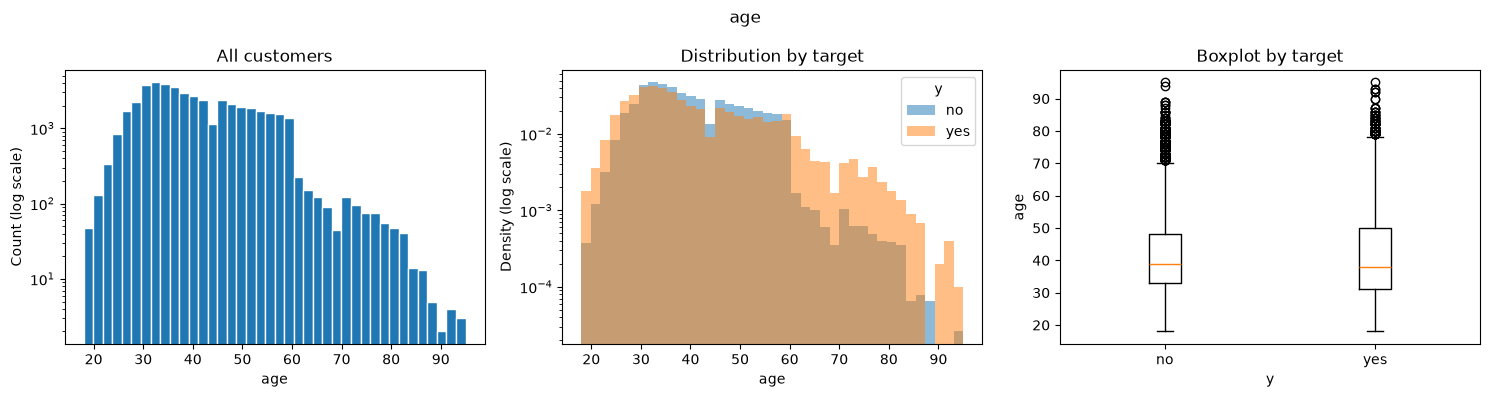

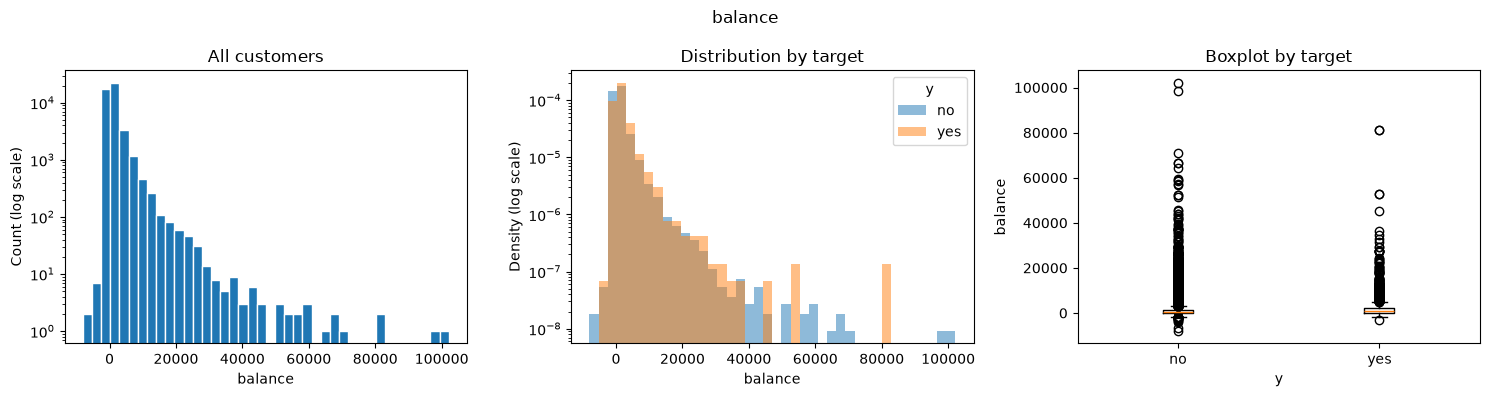

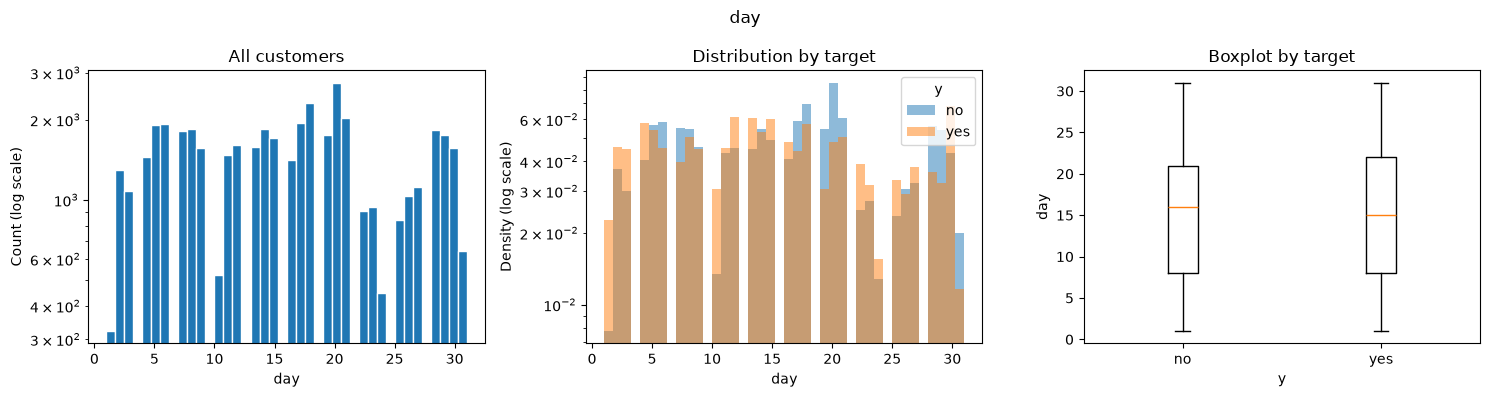

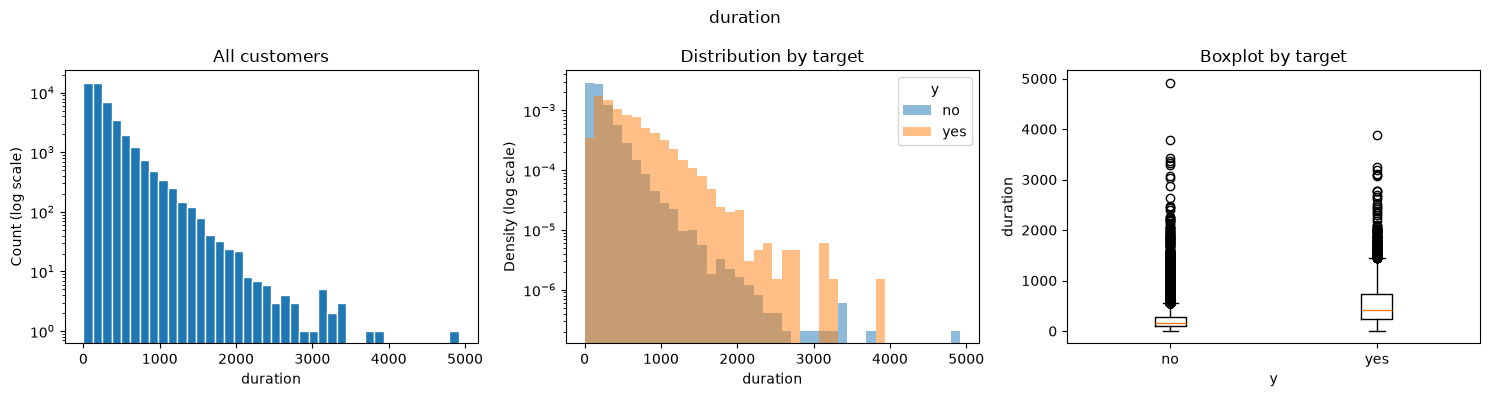

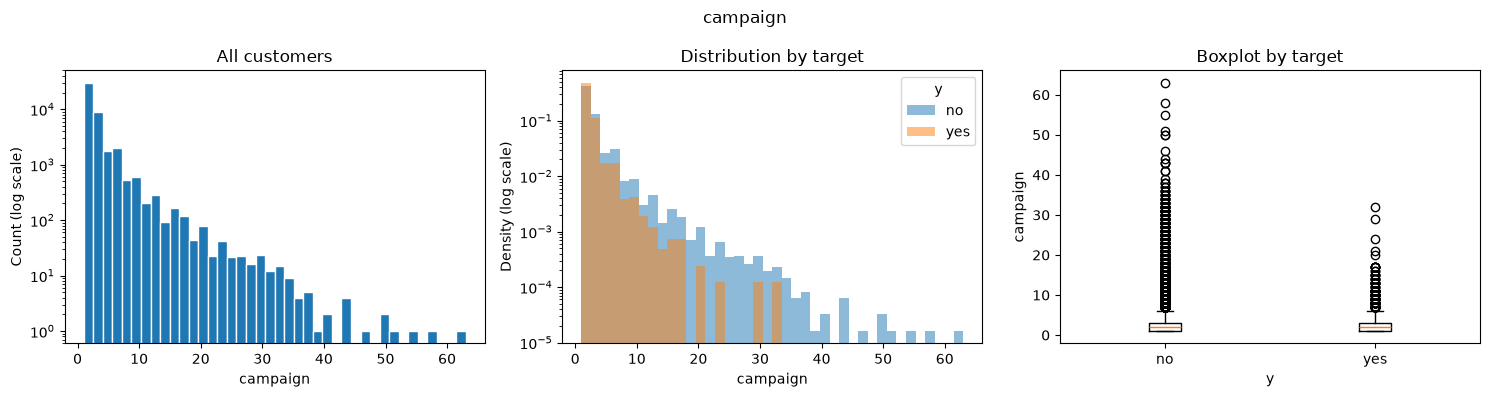

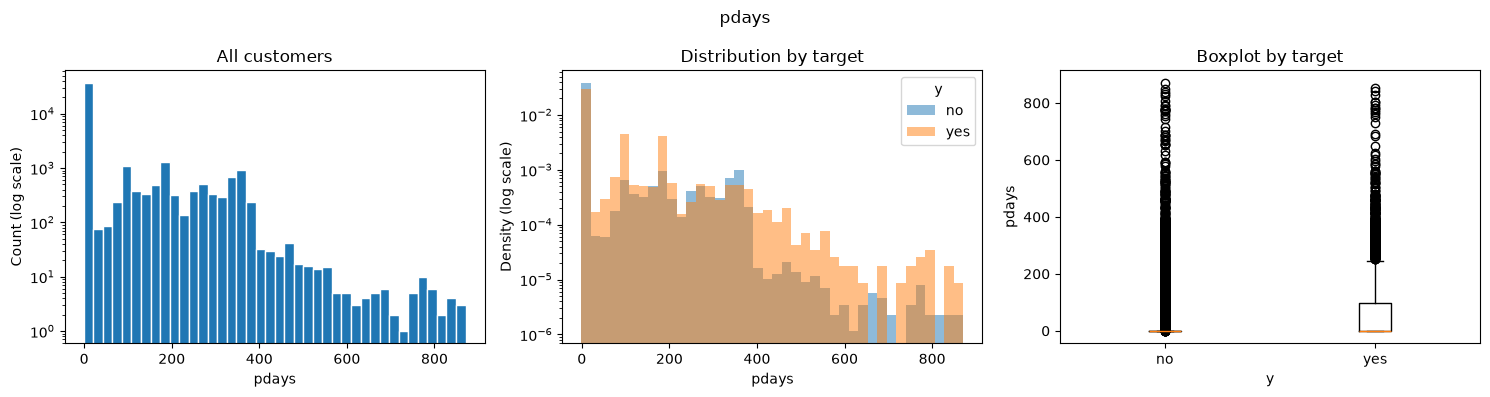

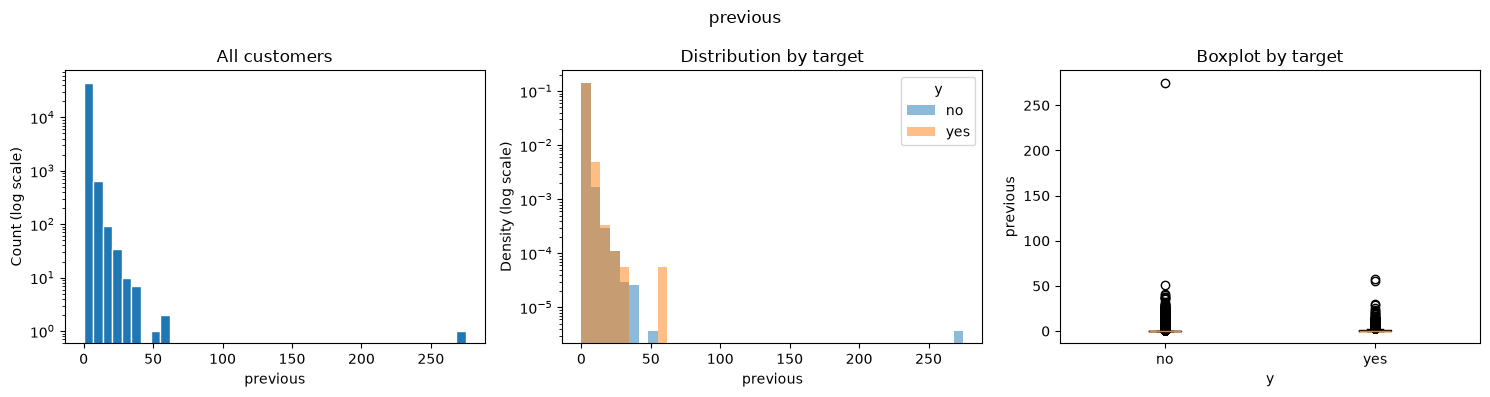

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

# plot numerical distributions and compare the target classes
for col in num_cols:
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    bins = np.histogram_bin_edges(df[col], bins=40)

    axes[0].hist(df[col], bins=bins, edgecolor="white")
    axes[0].set_yscale("log")
    axes[0].set_title("All customers")
    axes[0].set_xlabel(col)
    axes[0].set_ylabel("Count (log scale)")

    for label in ["no", "yes"]:
        values = df.loc[target == label, col]
        axes[1].hist(values, bins=bins, density=True, alpha=0.5, label=label)
    axes[1].set_yscale("log")
    axes[1].set_title("Distribution by target")
    axes[1].set_xlabel(col)
    axes[1].set_ylabel("Density (log scale)")
    axes[1].legend(title="y")

    groups = []
    for label in ["no", "yes"]:
        groups.append(df.loc[target == label, col])
    axes[2].boxplot(groups)
    axes[2].set_xticks([1, 2], ["no", "yes"])
    axes[2].set_title("Boxplot by target")
    axes[2].set_xlabel("y")
    axes[2].set_ylabel(col)

    fig.suptitle(col)
    plt.tight_layout()
    plt.show()


In [12]:
# compare numerical medians by target
num_summary = df.groupby("y")[num_cols].median()
num_summary


,age,balance,day,duration,campaign,pdays,previous
y,,,,,,,
no,39.0,417.0,16.0,164.0,2.0,-1.0,0.0
yes,38.0,733.0,15.0,426.0,2.0,-1.0,0.0


In [13]:
# check numerical ranges and IQR outliers
rows = []
for col in num_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    low = q1 - 1.5 * iqr
    high = q3 + 1.5 * iqr
    outliers = (df[col] < low) | (df[col] > high)
    rows.append([col, df[col].min(), q1, df[col].median(), q3,
                 df[col].max(), iqr, low, high, outliers.sum(), outliers.mean() * 100])

outlier_summary = pd.DataFrame(rows, columns=[
    "feature", "min", "q1", "median", "q3", "max", "iqr",
    "lower_fence", "upper_fence", "outlier_count", "outlier_percentage"
]).set_index("feature")
outlier_summary.round(2)


,min,q1,median,q3,max,iqr,lower_fence,upper_fence,outlier_count,outlier_percentage
feature,,,,,,,,,,
age,18,33.0,39.0,48.0,95,15.0,10.5,70.5,487,1.08
balance,-8019,72.0,448.0,1428.0,102127,1356.0,-1962.0,3462.0,4729,10.46
day,1,8.0,16.0,21.0,31,13.0,-11.5,40.5,0,0.00
duration,0,103.0,180.0,319.0,4918,216.0,-221.0,643.0,3235,7.16
campaign,1,1.0,2.0,3.0,63,2.0,-2.0,6.0,3064,6.78
pdays,-1,-1.0,-1.0,-1.0,871,0.0,-1.0,-1.0,8257,18.26
previous,0,0.0,0.0,0.0,275,0.0,0.0,0.0,8257,18.26


,age,balance,day,duration,campaign,pdays,previous,y
age,1.000,0.098,-0.009,-0.005,0.005,-0.024,0.001,0.025
balance,0.098,1.000,0.005,0.022,-0.015,0.003,0.017,0.053
day,-0.009,0.005,1.000,-0.030,0.162,-0.093,-0.052,-0.028
duration,-0.005,0.022,-0.030,1.000,-0.085,-0.002,0.001,0.395
campaign,0.005,-0.015,0.162,-0.085,1.000,-0.089,-0.033,-0.073
pdays,-0.024,0.003,-0.093,-0.002,-0.089,1.000,0.455,0.104
previous,0.001,0.017,-0.052,0.001,-0.033,0.455,1.000,0.093
y,0.025,0.053,-0.028,0.395,-0.073,0.104,0.093,1.000


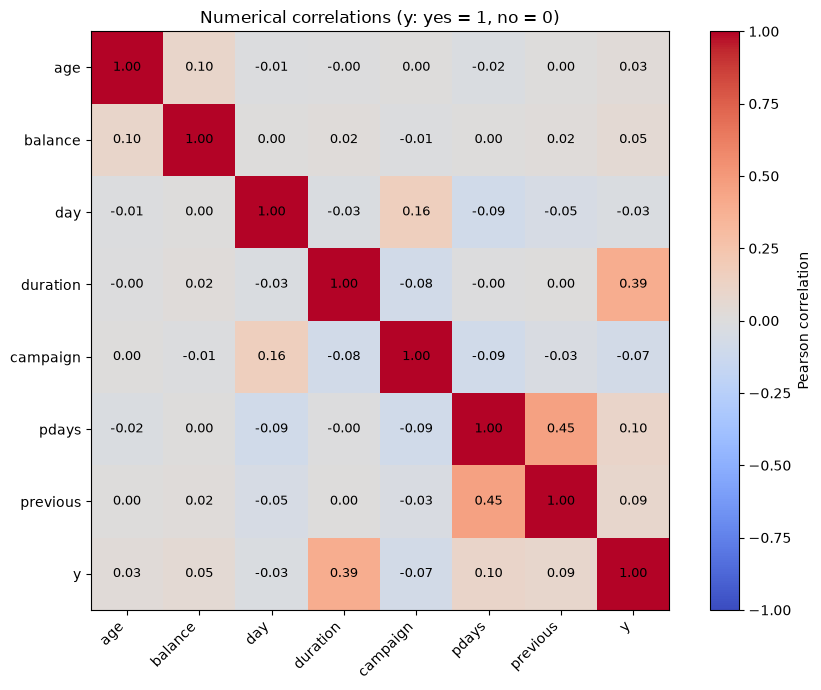

In [14]:
# encode the target without changing the original data
corr_data = df[num_cols].copy()
corr_data["y"] = target.map({"yes": 1, "no": 0})
corr = corr_data.corr()
display(corr.round(3))

# plot numerical and target correlations
fig, ax = plt.subplots(figsize=(9, 7))
heatmap = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr.columns)), corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr.columns)), corr.columns)
for i in range(len(corr.columns)):
    for j in range(len(corr.columns)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9)
fig.colorbar(heatmap, ax=ax, label="Pearson correlation")
ax.set_title("Numerical correlations (y: yes = 1, no = 0)")
plt.tight_layout()
plt.show()


Balance, duration, campaign, and previous have long right tails. Balance ranges from -8,019 to 102,127 euros; previous reaches 275 contacts. These values deserve review, but IQR flags alone do not establish errors, so no rows are removed. For pdays and previous, IQR is zero because most customers have no prior campaign contact; ordinary history values are therefore flagged too.

Subscribers have a median duration of 426 seconds versus 164 for non-subscribers, and median balance of 733 versus 417 euros. Duration has the largest numerical correlation with y (0.395); pdays and previous correlate at 0.455. Most other linear correlations are weak. The pdays sentinel affects its correlation, and day is a calendar value rather than a continuous measurement. Correlation does not establish causation or leakage.

## Categorical features

Percentages use all rows as the denominator. Subscription rates use the number of customers within each category. The dashed line is the overall subscription rate (11.70%).

In [15]:
# calculate category frequencies and subscription rates
cat_tables = {}
for col in cat_cols:
    table = pd.DataFrame({"count": df[col].value_counts()})
    yes_counts = df.loc[target == "yes", col].value_counts()
    table["yes_count"] = yes_counts.reindex(table.index, fill_value=0)
    table["percentage"] = table["count"] / len(df) * 100
    table["subscription_rate"] = table["yes_count"] / table["count"] * 100
    cat_tables[col] = table
    print(col)
    display(table.round(2))


job


,count,yes_count,percentage,subscription_rate
job,,,,
blue-collar,9732,708,21.53,7.27
management,9458,1301,20.92,13.76
technician,7597,840,16.80,11.06
admin.,5171,631,11.44,12.20
services,4154,369,9.19,8.88
retired,2264,516,5.01,22.79
self-employed,1579,187,3.49,11.84
entrepreneur,1487,123,3.29,8.27
unemployed,1303,202,2.88,15.50


marital


,count,yes_count,percentage,subscription_rate
marital,,,,
married,27214,2755,60.19,10.12
single,12790,1912,28.29,14.95
divorced,5207,622,11.52,11.95


education


...

,count,yes_count,percentage,subscription_rate
contact,,,,
cellular,29285,4369,64.77,14.92
unknown,13020,530,28.80,4.07
telephone,2906,390,6.43,13.42


month


,count,yes_count,percentage,subscription_rate
month,,,,
may,13766,925,30.45,6.72
jul,6895,627,15.25,9.09
aug,6247,688,13.82,11.01
jun,5341,546,11.81,10.22
nov,3970,403,8.78,10.15
apr,2932,577,6.49,19.68
feb,2649,441,5.86,16.65
jan,1403,142,3.10,10.12
oct,738,323,1.63,43.77


poutcome


,count,yes_count,percentage,subscription_rate
poutcome,,,,
unknown,36959,3386,81.75,9.16
failure,4901,618,10.84,12.61
other,1840,307,4.07,16.68
success,1511,978,3.34,64.73


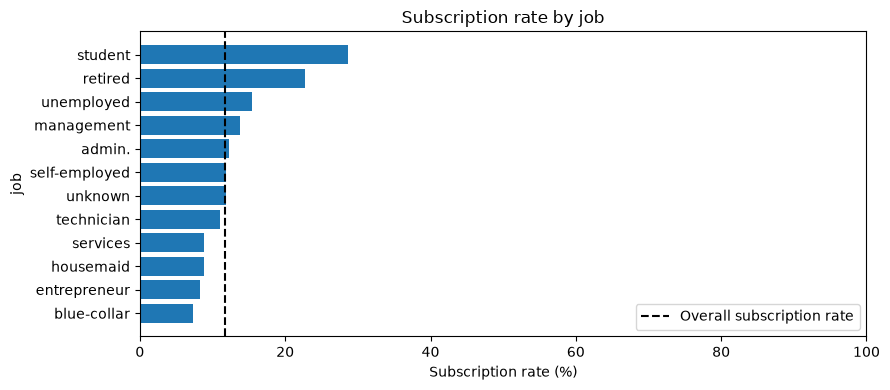

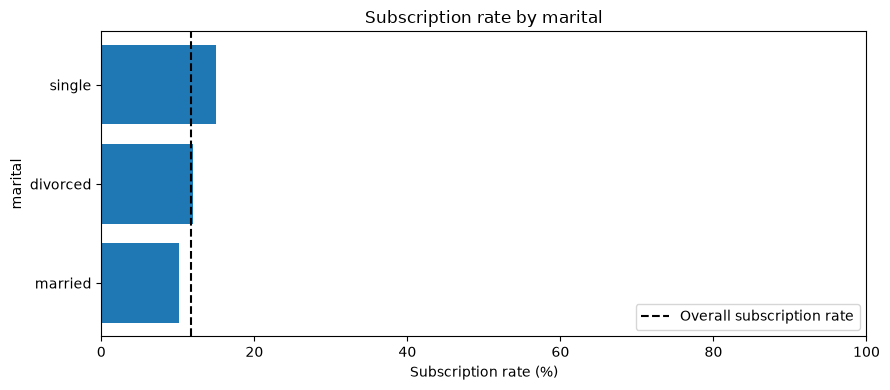

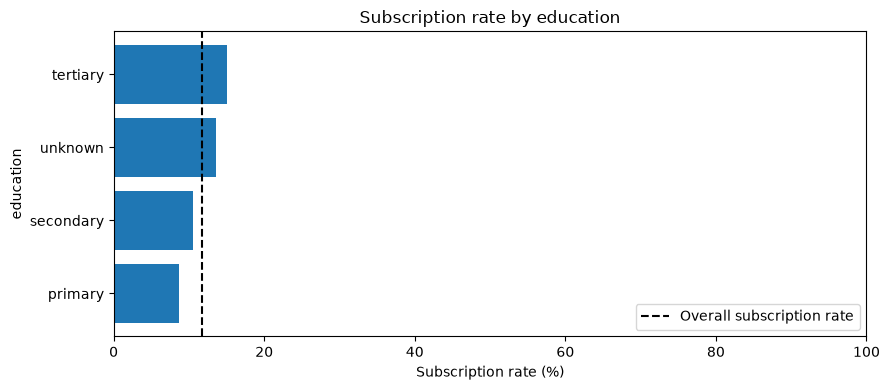

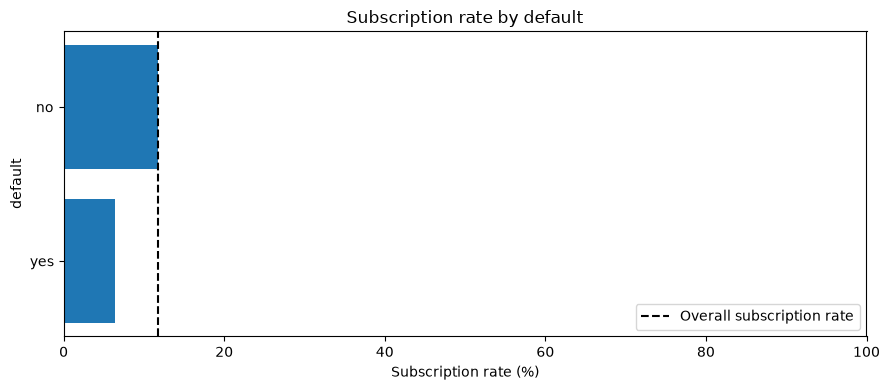

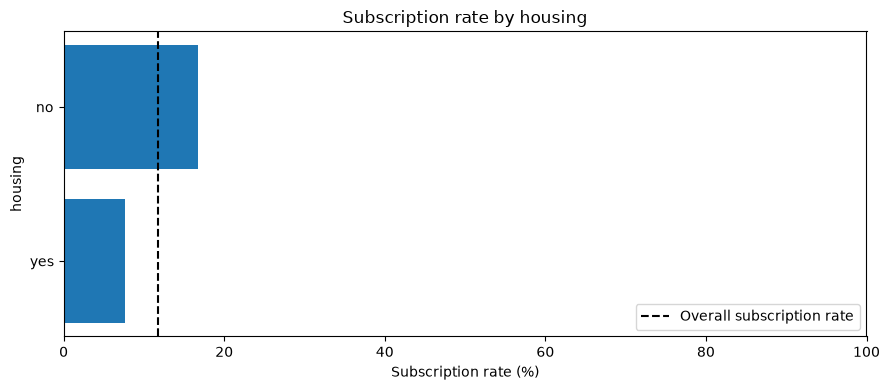

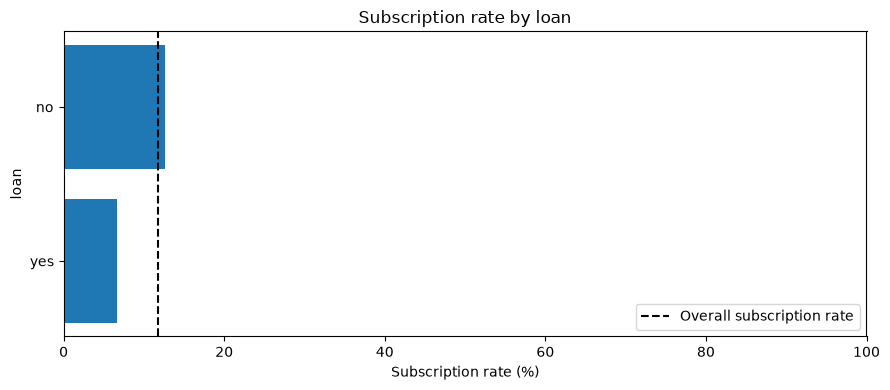

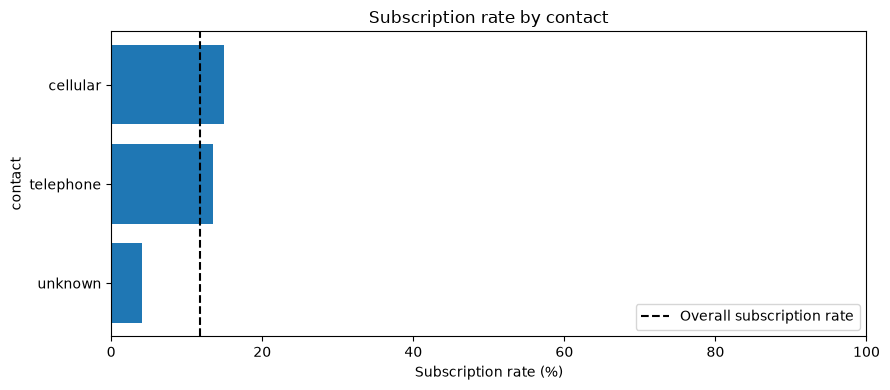

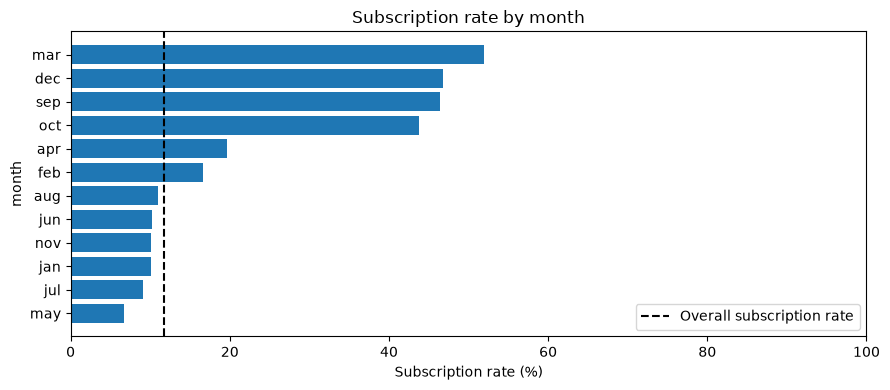

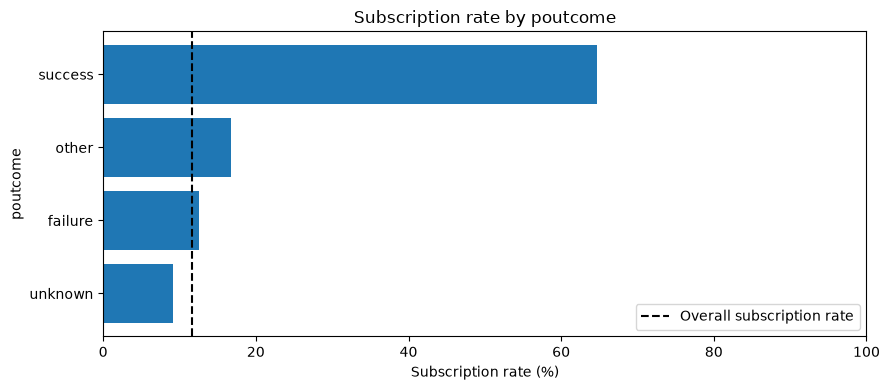

In [16]:
# compare subscription rates across categories
for col in cat_cols:
    rates = cat_tables[col]["subscription_rate"].sort_values()
    plt.figure(figsize=(9, 4))
    plt.barh(rates.index, rates.values)
    plt.axvline((target == "yes").mean() * 100, color="black", linestyle="--",
                label="Overall subscription rate")
    plt.xlim(0, 100)
    plt.xlabel("Subscription rate (%)")
    plt.ylabel(col)
    plt.title("Subscription rate by " + col)
    plt.legend(loc="lower right")
    plt.tight_layout()
    plt.show()


Previous campaign success has a 64.73% subscription rate versus 9.16% for unknown outcomes. Students (28.68%) and retired customers (22.79%) have higher rates than blue-collar customers (7.27%). Customers without housing loans have a 16.70% rate versus 7.70% with housing loans; personal-loan rates are 12.66% without versus 6.68% with a loan.

Single customers have a 14.95% rate versus 10.12% for married customers; tertiary education has 15.01% versus 8.63% for primary. Rates are 6.38% for customers in default versus 11.80% otherwise, but only 815 customers are in default. Cellular contacts have 14.92% versus 4.07% for unknown contact type. March (51.99%) and May (6.72%) differ sharply, with only 477 March records versus 13,766 in May. These are descriptive differences; sample sizes and campaign selection can affect them.

## Missing and unknown values

In [17]:
# check actual missing values separately
missing_summary = pd.DataFrame({"count": df.isna().sum()})
missing_summary["percentage"] = missing_summary["count"] / len(df) * 100
missing_summary


,count,percentage
age,0,0.0
job,0,0.0
marital,0,0.0
education,0,0.0
default,0,0.0
balance,0,0.0
housing,0,0.0
loan,0,0.0
contact,0,0.0
day,0,0.0


In [18]:
# count unknown values without replacing them
rows = []
for col in cat_cols:
    count = (df[col] == "unknown").sum()
    if count > 0:
        rows.append([col, count, count / len(df) * 100])

unknown_summary = pd.DataFrame(rows, columns=["feature", "count", "percentage"])
unknown_summary = unknown_summary.set_index("feature")
unknown_summary.round(2)


,count,percentage
feature,,
job,288,0.64
education,1857,4.11
contact,13020,28.80
poutcome,36959,81.75


In [19]:
# check the special pdays value
not_contacted = df["pdays"] == -1
pdays_summary = pd.DataFrame({
    "count": [not_contacted.sum(), (~not_contacted).sum()]
}, index=["No previous campaign contact (-1)", "Previous campaign contact"])
pdays_summary["percentage"] = pdays_summary["count"] / len(df) * 100
display(pdays_summary.round(2))

# compare the sentinel with the previous contact count
print("Rows with pdays = -1 and previous > 0:",
      (not_contacted & (df["previous"] > 0)).sum())
print("Rows with pdays != -1 and previous = 0:",
      ((~not_contacted) & (df["previous"] == 0)).sum())
print("Days since contact for customers with previous campaign contact:")
display(df.loc[~not_contacted, "pdays"].describe().round(2))


,count,percentage
No previous campaign contact (-1),36954,81.74
Previous campaign contact,8257,18.26


Rows with pdays = -1 and previous > 0: 0
Rows with pdays != -1 and previous = 0: 0
Days since contact for customers with previous campaign contact:


count    8257.00
mean      224.58
std       115.34
min         1.00
25%       133.00
50%       194.00
75%       327.00
max       871.00
Name: pdays, dtype: float64

There are no actual missing values. Unknown values occur in job (288; 0.64%), education (1,857; 4.11%), contact (13,020; 28.80%), and poutcome (36,959; 81.75%). Contact and poutcome need particular attention because unknown values dominate or form a large group. Unknown remains a separate category throughout this EDA.

In the [UCI bank-full definitions](https://archive.ics.uci.edu/dataset/222/bank+marketing), pdays = -1 means no previous campaign contact. It occurs in 36,954 rows (81.74%), consistently with previous = 0. It is a history indicator, not a negative elapsed time or an actual missing value. Unknown poutcome does not necessarily mean no previous contact: there are five more unknown outcomes than -1 records. Future preprocessing could separate the no-history indicator from elapsed days; this EDA leaves the values unchanged.

## Leakage and feature recommendations

Prediction timing: immediately before dialing the current scheduled call, after its date, channel, and attempt number have been fixed, using customer and history records available at that time. Availability below is an inference from the [UCI bank-full definitions](https://archive.ics.uci.edu/dataset/222/bank+marketing), not proof of the bank's recording workflow.

| Predictor | Meaning and availability | Decision at this timing |
| --- | --- | --- |
| duration | Current call length; accumulates during the call and is final only afterward. | Exclude: unavailable before calling, so it leaks post-contact information. |
| campaign | Current campaign contact count, including this contact. Earlier attempts are known before calling; the recorded count includes the current attempt. | Keep only as the already-fixed current attempt number, reconstructible as prior attempts + 1; never use a later final campaign total. |
| pdays | Elapsed days since contact in a previous campaign; -1 indicates no such history. | Keep as history, calculated at the prediction date. |
| previous | Contacts before this campaign. | Keep: available from prior history. |
| poutcome | Previous campaign result. | Keep: available from a completed earlier campaign, not this call's outcome. |
| contact | Current contact channel. Planned before dialing; actual channel confirmed during contact. | Keep only if the planned channel matches the recorded value. |
| day | Day of the current recorded contact. | Keep only for the scheduled call date known before dialing. |
| month | Month of the current recorded contact. | Keep only for the scheduled call date known before dialing. |

Duration causes leakage because a pre-call model cannot know how long the call will last. Its strong association with y does not itself establish leakage; availability at prediction time does. Prior campaign outcomes can be strongly associated with y and still be valid history.

This timing assumes the planned contact, day, month, and attempt number match the CSV's last-contact fields. Verify that assumption in the operational data. For earlier customer selection, before a call is scheduled, omit these four fields too; do not substitute a later contact's recorded values. Customer attributes must also reflect information already held before the call.

In [20]:
# keep every predictor for exploratory comparison
all_features = features.columns.tolist()

# exclude information that becomes available during or after this call
pre_contact_features = []
for col in all_features:
    if col != "duration":
        pre_contact_features.append(col)

print("All features:", all_features)
print("Pre-contact features:", pre_contact_features)


All features: ['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome']
Pre-contact features: ['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'campaign', 'pdays', 'previous', 'poutcome']


Use pre_contact_features (15 predictors) for primary modeling at the stated scheduled-call timing. Keep all_features (16 predictors, including duration) for exploratory comparison only. Excluding call duration makes evaluation closer to a real pre-call decision; including it would give the model information unavailable when the decision is made. The other timing assumptions above still require verification.

02_preprocessing.ipynb currently uses 11 predictors and excludes default, day, duration, pdays, and poutcome. Both recommendations exclude duration. This EDA additionally retains default, day, pdays, and poutcome under the stated timing. The preprocessing notebook documents preliminary reasons: default is imbalanced, day may reflect unstable scheduling, pdays needs sentinel handling, and poutcome was omitted for simplicity. Those are feature-selection or data-handling choices, rather than evidence that the four fields inherently leak the current outcome. Compare their value using training/validation data before changing the shared modeling setup. The preprocessing notebook is unchanged.